In [ ]:
!pip install qutip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 24.6 MB/s  0:00:01


In [ ]:
!pip install scqubits

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 77.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scqubits]


In [4]:
import scqubits as scq
import qutip as qt
import numpy as np
import matplotlib.pyplot as plt



Energy levels relative to ground state (GHz):
E0 - E0 = 0.000000 GHz
E1 - E0 = 6.063469 GHz
E2 - E0 = 11.849553 GHz
E3 - E0 = 17.334049 GHz
E4 - E0 = 22.482857 GHz
E5 - E0 = 27.259789 GHz

f01 = 6.063469 GHz
f12 = 5.786084 GHz
Anharmonicity = -0.277386 GHz


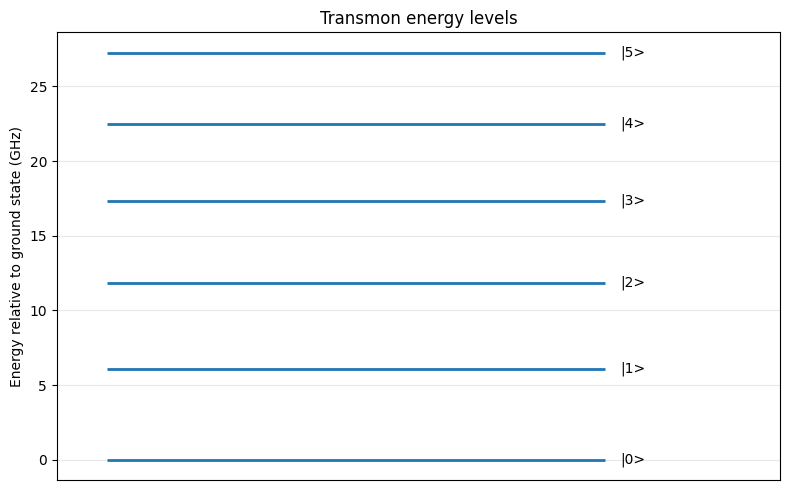

In [5]:
import scqubits as scq
import numpy as np
import matplotlib.pyplot as plt

# All energy parameters are expressed in GHz (E/h)
transmon = scq.Transmon(
    EJ=20.0,
    EC=0.25,
    ng=0.0,
    ncut=35,
    truncated_dim=6
)

# Calculate the lowest six energy eigenvalues
energies = transmon.eigenvals(evals_count=6)

# Transition frequencies relative to the ground state
transition_freqs = energies - energies[0]

print("Energy levels relative to ground state (GHz):")
for i, freq in enumerate(transition_freqs):
    print(f"E{i} - E0 = {freq:.6f} GHz")

f01 = energies[1] - energies[0]
f12 = energies[2] - energies[1]
anharmonicity = f12 - f01

print(f"\nf01 = {f01:.6f} GHz")
print(f"f12 = {f12:.6f} GHz")
print(f"Anharmonicity = {anharmonicity:.6f} GHz")

# Plot energy transitions
plt.figure(figsize=(8, 5))

for i, energy in enumerate(transition_freqs):
    plt.hlines(
        energy, 0, 1,
        linewidth=2
    )
    plt.text(
        1.03, energy, f"|{i}>",
        va="center"
    )

plt.xlim(-0.1, 1.35)
plt.xticks([])
plt.ylabel("Energy relative to ground state (GHz)")
plt.title("Transmon energy levels")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

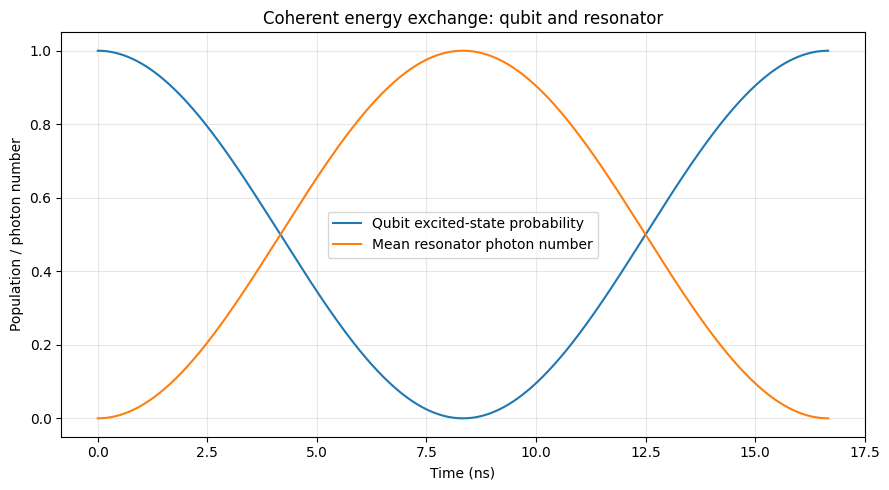

Coupling g/(2*pi) = 30.0 MHz
First excitation-transfer time = 8.333 ns


In [6]:

import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

# Reuse f01 calculated using scqubits
fr = f01                 # Resonator frequency in GHz
fq = f01                 # Qubit frequency in GHz
g_hz = 0.030             # g/(2*pi), in GHz = 30 MHz
g = 2 * np.pi * g_hz     # Angular coupling, rad/ns

# Hilbert-space dimensions
Nq = 2
Nr = 4

# Qubit operators: |g> = |0>, |e> = |1>
sm = qt.basis(Nq, 0) * qt.basis(Nq, 1).dag()
sp = sm.dag()
Pe = qt.basis(Nq, 1) * qt.basis(Nq, 1).dag()

# Resonator operators
a = qt.destroy(Nr)
I_q = qt.qeye(Nq)
I_r = qt.qeye(Nr)

# Rotating-frame Jaynes-Cummings Hamiltonian.
# At resonance, both detuning terms are zero.
H = g * (
    qt.tensor(sp, a)
    + qt.tensor(sm, a.dag())
)

# Initial state: excited qubit, zero resonator photons
psi0 = qt.tensor(
    qt.basis(Nq, 1),
    qt.basis(Nr, 0)
)

# Operators to measure
P_excited = qt.tensor(Pe, I_r)
N_photons = qt.tensor(I_q, a.dag() * a)

# Time is in ns
t_swap = np.pi / (2 * g)
times = np.linspace(0, 2 * t_swap, 500)

result = qt.sesolve(H, psi0, times, e_ops=[
    P_excited,
    N_photons
])

P_e = np.real(result.expect[0])
n_photons = np.real(result.expect[1])

# Plot qubit excitation and resonator photon occupation
plt.figure(figsize=(9, 5))
plt.plot(times, P_e, label="Qubit excited-state probability")
plt.plot(times, n_photons, label="Mean resonator photon number")
plt.xlabel("Time (ns)")
plt.ylabel("Population / photon number")
plt.title("Coherent energy exchange: qubit and resonator")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Coupling g/(2*pi) = {g_hz*1000:.1f} MHz")
print(f"First excitation-transfer time = {t_swap:.3f} ns")


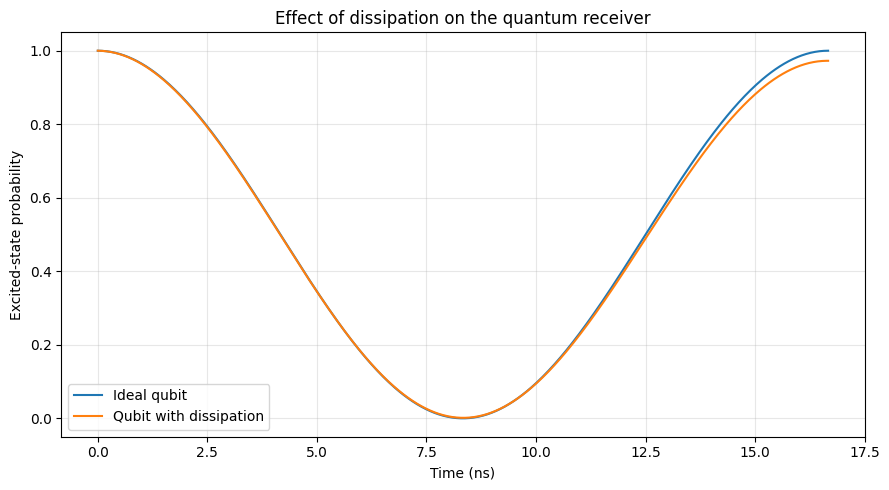

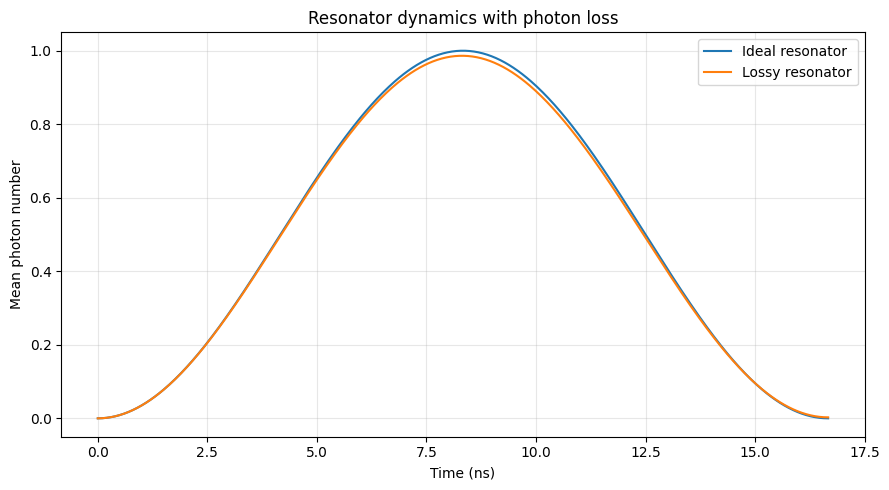

In [7]:

import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

# Use the same H, psi0, times, P_excited and N_photons
# defined in Simulation 2.

# Illustrative rates in inverse nanoseconds
kappa = 1 / 500       # Resonator photon-number decay rate
gamma1 = 1 / 1000     # Qubit relaxation rate
gamma_phi = 1 / 1500  # Pure dephasing rate

# Relaxation and resonator-loss collapse operators
c_ops = [
    np.sqrt(kappa) * qt.tensor(I_q, a),
    np.sqrt(gamma1) * qt.tensor(sm, I_r),
]

# Pure dephasing: sigma_z / 2
sz = qt.sigmaz()
c_ops.append(
    np.sqrt(gamma_phi / 2) * qt.tensor(sz, I_r)
)

# Closed-system and open-system evolution
ideal = qt.sesolve(
    H, psi0, times,
    e_ops=[P_excited, N_photons]
)

open_result = qt.mesolve(
    H, qt.ket2dm(psi0), times,
    c_ops=c_ops,
    e_ops=[P_excited, N_photons]
)

# Compare qubit excitation
plt.figure(figsize=(9, 5))
plt.plot(
    times, np.real(ideal.expect[0]),
    label="Ideal qubit"
)
plt.plot(
    times, np.real(open_result.expect[0]),
    label="Qubit with dissipation"
)
plt.xlabel("Time (ns)")
plt.ylabel("Excited-state probability")
plt.title("Effect of dissipation on the quantum receiver")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Compare photon occupation
plt.figure(figsize=(9, 5))
plt.plot(
    times, np.real(ideal.expect[1]),
    label="Ideal resonator"
)
plt.plot(
    times, np.real(open_result.expect[1]),
    label="Lossy resonator"
)
plt.xlabel("Time (ns)")
plt.ylabel("Mean photon number")
plt.title("Resonator dynamics with photon loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


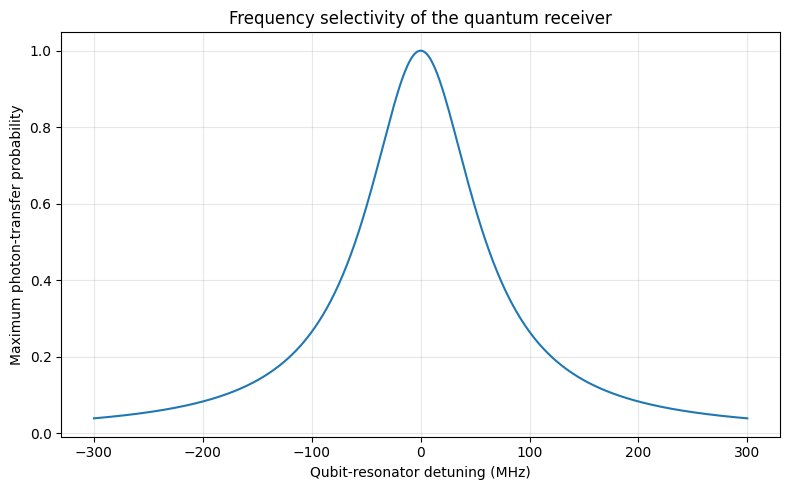

In [8]:

import numpy as np
import matplotlib.pyplot as plt

# Detuning in GHz, expressed as ordinary frequency
detuning = np.linspace(-0.30, 0.30, 500)
g_hz = 0.030

# Ideal maximum resonator photon occupation
Pmax = 4 * g_hz**2 / (
    detuning**2 + 4 * g_hz**2
)

plt.figure(figsize=(8, 5))
plt.plot(detuning * 1000, Pmax)
plt.xlabel("Qubit-resonator detuning (MHz)")
plt.ylabel("Maximum photon-transfer probability")
plt.title("Frequency selectivity of the quantum receiver")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:
import scqubits as scq
import numpy as np

transmon = scq.Transmon(
    EJ=20.0,
    EC=0.25,
    ng=0.0,
    ncut=35,
    truncated_dim=6
)

# Energy eigenvalues
energies = transmon.eigenvals(evals_count=6)

# Charge operator in the energy eigenbasis
n_operator = transmon.n_operator(
    energy_esys=True
)

n01 = abs(n_operator[0, 1])

f01 = energies[1] - energies[0]
f12 = energies[2] - energies[1]

print("f01:", f01, "GHz")
print("f12:", f12, "GHz")
print("Anharmonicity:", f12 - f01, "GHz")
print("|n01|:", n01)

f01: 6.063469337990849 GHz
f12: 5.7860835142722005 GHz
Anharmonicity: -0.2773858237186486 GHz
|n01|: 1.2310412987696895


In [11]:
import numpy as np

# Physical constants
e = 1.602176634e-19
hbar = 1.054571817e-34

# Illustrative resonator parameters
fr = 6.0e9
Cr = 100e-15

# Coupling capacitance and total transmon capacitance
Cg = 5e-15
Cq = 80e-15

beta = Cg / (Cg + Cq)

# Resonator zero-point voltage
wr = 2 * np.pi * fr

Vzpf = np.sqrt(
    hbar * wr / (2 * Cr)
)

# Coupling in angular frequency units
g = (
    2 * e * beta * Vzpf * n01 / hbar
)

print("Zero-point voltage:", Vzpf, "V")
print("g/(2*pi):", g/(2*np.pi)/1e6, "MHz")

Zero-point voltage: 4.4584986753188835e-06 V
g/(2*pi): 156.13371870429205 MHz


In [12]:
import scqubits as scq

transmon = scq.Transmon(
    EJ=20.0,
    EC=0.25,
    ng=0.0,
    ncut=35,
    truncated_dim=6
)

resonator = scq.Oscillator(
    E_osc=transmon.eigenvals(evals_count=2)[1]
          - transmon.eigenvals(evals_count=2)[0],
    truncated_dim=10
)

hilbert_space = scq.HilbertSpace(
    [transmon, resonator]
)

In [13]:
for cutoff in [25, 30, 35, 40, 45]:

    tq = scq.Transmon(
        EJ=20.0,
        EC=0.25,
        ng=0.0,
        ncut=cutoff,
        truncated_dim=3
    )

    ev = tq.eigenvals(evals_count=3)

    print(
        cutoff,
        ev[1] - ev[0],
        ev[2] - 2*ev[1] + ev[0]
    )

25 6.063469337990769 -0.27738582371851095
30 6.063469337990757 -0.27738582371853227
35 6.063469337990744 -0.2773858237184328
40 6.063469337990746 -0.2773858237185465
45 6.063469337990647 -0.2773858237183404
